In [1]:
import os
import time
import json
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report

# 1. Menjaga Reproduksibilitas (Deterministic Seed)
SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat Komputasi: {device}")
if torch.cuda.is_available():
    print(f"Nama GPU: {torch.cuda.get_device_name(0)}")

KeyboardInterrupt: 

In [ ]:
# 1. Download Dataset Penuh Oxford-IIIT Pet
data_dir = "./data"
raw_trainval = OxfordIIITPet(root=data_dir, split="trainval", target_types="category", download=True)
raw_test = OxfordIIITPet(root=data_dir, split="test", target_types="category", download=True)

# Gabungkan seluruh gambar dan label
all_images = raw_trainval._images + raw_test._images
all_labels = raw_trainval._labels + raw_test._labels
classes = raw_trainval.classes

# 2. Pemetaan nama kelas secara case-insensitive
# 5 Kucing dan 5 Anjing sesuai arahan tugas
target_breed_names = [
    'abyssinian', 'bengal', 'birman', 'bombay', 'british shorthair', # Kucing
    'beagle', 'boxer', 'chihuahua', 'english cocker spaniel', 'german shorthaired' # Anjing
]

# Cocokkan nama target dengan string asli di dataset
normalized_class_lookup = {c.lower().replace('_', ' '): c for c in classes}
selected_classes = []
for name in target_breed_names:
    norm_name = name.lower().replace('_', ' ')
    if norm_name in normalized_class_lookup:
        selected_classes.append(normalized_class_lookup[norm_name])

print(f"Kelas terpilih di dataset: {selected_classes}")

selected_class_to_idx = {name: i for i, name in enumerate(selected_classes)}
original_selected_indices = [classes.index(name) for name in selected_classes]

# Filter dataset hanya untuk 10 kelas terpilih
filtered_images = []
filtered_labels = []

for img_path, orig_lbl in zip(all_images, all_labels):
    if orig_lbl in original_selected_indices:
        class_name = classes[orig_lbl]
        new_label = selected_class_to_idx[class_name]
        filtered_images.append(img_path)
        filtered_labels.append(new_label)

filtered_labels = np.array(filtered_labels)
print(f"Total citra dari 10 kelas terpilih: {len(filtered_images)}")

# 3. Stratified Split: 70% Train, 15% Validation, 15% Test
indices = np.arange(len(filtered_images))
train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, filtered_labels, test_size=0.30, stratify=filtered_labels, random_state=SEED
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print(f"Jumlah sampel -> Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

Kelas terpilih di dataset: ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair', 'Beagle', 'Boxer', 'Chihuahua', 'English Cocker Spaniel', 'German Shorthaired']
Total citra dari 10 kelas terpilih: 1977
Jumlah sampel -> Train: 1383 | Val: 297 | Test: 297


In [ ]:
class CustomPetSubset(Dataset):
    """Dataset wrapper kustom untuk menerapkan transformasi citra secara dinamis"""
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)
        return image, label

# Normalisasi Standar ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Pipeline Transformasi
# A. Dengan Augmentasi Aktif (Data Latih Standar)
train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# B. Tanpa Augmentasi (Hanya Resize, CenterCrop, & Normalisasi)
transforms_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Subset data paths dan label
train_paths = [filtered_images[i] for i in train_idx]
val_paths = [filtered_images[i] for i in val_idx]
test_paths = [filtered_images[i] for i in test_idx]

# DataLoader generator helper
BATCH_SIZE = 32

def get_dataloaders(use_train_augmentation=True):
    t_transform = train_transforms_aug if use_train_augmentation else transforms_no_aug
    
    ds_train = CustomPetSubset(train_paths, y_train, transform=t_transform)
    ds_val = CustomPetSubset(val_paths, y_val, transform=transforms_no_aug)
    ds_test = CustomPetSubset(test_paths, y_test, transform=transforms_no_aug)

    # Ubah num_workers menjadi 0 agar stabil di Windows
    loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
    loader_val = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
    loader_test = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

    return loader_train, loader_val, loader_test

In [ ]:
class EarlyStopping:
    """Menghentikan pelatihan apabila validation loss tidak membaik setelah N epoch"""
    def __init__(self, patience=4, delta=0.0):
        self.patience = patience
        self.delta = delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_weights = None

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model_weights = copy.deepcopy(model.state_dict())
        elif val_loss > self.best_loss - self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model_weights = copy.deepcopy(model.state_dict())
            self.counter = 0


def train_and_evaluate(model, optimizer, criterion, train_loader, val_loader, test_loader, 
                       max_epochs=25, patience=4):
    """Pipeline terpadu untuk training loop, early stopping, dan evaluasi test set"""
    early_stopping = EarlyStopping(patience=patience)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    start_time = time.time()
    converged_epoch = 0

    for epoch in range(1, max_epochs + 1):
        # --- Fase Latih ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += torch.sum(preds == labels.data).item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        # --- Fase Validasi ---
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct_val += torch.sum(preds == labels.data).item()
                total_val += labels.size(0)

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        converged_epoch = epoch

        # Cek Early Stopping
        early_stopping(epoch_val_loss, model)
        if early_stopping.early_stop:
            print(f"Early stopping aktif pada epoch {epoch}!")
            break

    total_training_time = time.time() - start_time

    # Muat bobot terbaik yang tersimpan saat validation loss minimum
    if early_stopping.best_model_weights is not None:
        model.load_state_dict(early_stopping.best_model_weights)

    # --- Evaluasi Akhir pada Test Set ---
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.numpy())

    test_acc = accuracy_score(all_targets, all_preds)
    test_macro_f1 = f1_score(all_targets, all_preds, average='macro')
    best_val_acc = max(history['val_acc'])

    return {
        'history': history,
        'converged_epoch': converged_epoch,
        'training_time': total_training_time,
        'val_acc': best_val_acc,
        'test_acc': test_acc,
        'test_macro_f1': test_macro_f1,
        'best_model': model,
        'test_preds': all_preds,
        'test_targets': all_targets
    }

In [ ]:
results_log = []
histories = {}
trained_models = {}
criterion = nn.CrossEntropyLoss()

# Dataloaders default (dengan augmentasi aktif)
train_loader_aug, val_loader, test_loader = get_dataloaders(use_train_augmentation=True)
# Dataloaders tanpa augmentasi untuk uji kontrol B4
train_loader_no_aug, _, _ = get_dataloaders(use_train_augmentation=False)

# =====================================================================
# B1: Baseline from Scratch (ResNet-18 tanpa Pretrained Weights)
# =====================================================================
print("\n--- Menjalankan B1: Baseline from Scratch ---")
set_seed(SEED)
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1 = model_b1.to(device)

opt_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)
trainable_b1 = sum(p.numel() for p in model_b1.parameters() if p.requires_grad)

res_b1 = train_and_evaluate(model_b1, opt_b1, criterion, train_loader_aug, val_loader, test_loader)
histories['B1'] = res_b1['history']
results_log.append({
    'Kode': 'B1',
    'Kondisi': 'Baseline from Scratch',
    'Backbone': 'ResNet-18',
    'Trainable_Params': trainable_b1,
    'Learning_Rate': '1e-3',
    'Epoch_Konvergen': res_b1['converged_epoch'],
    'Durasi_Detik': round(res_b1['training_time'], 2),
    'Val_Accuracy': round(res_b1['val_acc'], 4),
    'Test_Macro_F1': round(res_b1['test_macro_f1'], 4)
})

# =====================================================================
# B2: Feature Extraction (ResNet-18 Bekukan Backbone)
# =====================================================================
print("\n--- Menjalankan B2: Feature Extraction ---")
set_seed(SEED)
weights_resnet = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights_resnet)
for param in model_b2.parameters():
    param.requires_grad = False
model_b2.fc = nn.Linear(model_b2.fc.in_features, 10)
model_b2 = model_b2.to(device)

opt_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)
trainable_b2 = sum(p.numel() for p in model_b2.parameters() if p.requires_grad)

res_b2 = train_and_evaluate(model_b2, opt_b2, criterion, train_loader_aug, val_loader, test_loader)
histories['B2'] = res_b2['history']
results_log.append({
    'Kode': 'B2',
    'Kondisi': 'Feature Extraction',
    'Backbone': 'ResNet-18',
    'Trainable_Params': trainable_b2,
    'Learning_Rate': '1e-3 (fc)',
    'Epoch_Konvergen': res_b2['converged_epoch'],
    'Durasi_Detik': round(res_b2['training_time'], 2),
    'Val_Accuracy': round(res_b2['val_acc'], 4),
    'Test_Macro_F1': round(res_b2['test_macro_f1'], 4)
})

# =====================================================================
# B3: Progressive Fine-Tuning (Unfreeze layer4 + fc dengan Diff LR)
# =====================================================================
print("\n--- Menjalankan B3: Progressive Fine-Tuning ---")
set_seed(SEED)
model_b3 = models.resnet18(weights=weights_resnet)
for param in model_b3.parameters():
    param.requires_grad = False
for param in model_b3.layer4.parameters():
    param.requires_grad = True
model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)
model_b3 = model_b3.to(device)

opt_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)
trainable_b3 = sum(p.numel() for p in model_b3.parameters() if p.requires_grad)

res_b3 = train_and_evaluate(model_b3, opt_b3, criterion, train_loader_aug, val_loader, test_loader)
histories['B3'] = res_b3['history']
trained_models['B3'] = res_b3['best_model']
results_log.append({
    'Kode': 'B3',
    'Kondisi': 'Progressive Fine-Tuning',
    'Backbone': 'ResNet-18',
    'Trainable_Params': trainable_b3,
    'Learning_Rate': 'layer4=1e-4, fc=1e-3',
    'Epoch_Konvergen': res_b3['converged_epoch'],
    'Durasi_Detik': round(res_b3['training_time'], 2),
    'Val_Accuracy': round(res_b3['val_acc'], 4),
    'Test_Macro_F1': round(res_b3['test_macro_f1'], 4)
})

# =====================================================================
# B4: Uji Kontrol Data Augmentation (Menggunakan konfigurasi B3 Tanpa Aug)
# =====================================================================
print("\n--- Menjalankan B4: Uji Kontrol Data Augmentation (Tanpa Augmentasi) ---")
set_seed(SEED)
model_b4 = models.resnet18(weights=weights_resnet)
for param in model_b4.parameters():
    param.requires_grad = False
for param in model_b4.layer4.parameters():
    param.requires_grad = True
model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
model_b4 = model_b4.to(device)

opt_b4 = torch.optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

res_b4 = train_and_evaluate(model_b4, opt_b4, criterion, train_loader_no_aug, val_loader, test_loader)
histories['B4'] = res_b4['history']
results_log.append({
    'Kode': 'B4',
    'Kondisi': 'Fine-Tuning Tanpa Augmentasi',
    'Backbone': 'ResNet-18',
    'Trainable_Params': trainable_b3,
    'Learning_Rate': 'layer4=1e-4, fc=1e-3',
    'Epoch_Konvergen': res_b4['converged_epoch'],
    'Durasi_Detik': round(res_b4['training_time'], 2),
    'Val_Accuracy': round(res_b4['val_acc'], 4),
    'Test_Macro_F1': round(res_b4['test_macro_f1'], 4)
})

# =====================================================================
# B5: Arsitektur Pembanding (Bonus: EfficientNet-B0)
# =====================================================================
print("\n--- Menjalankan B5: Arsitektur Pembanding (EfficientNet-B0) ---")
set_seed(SEED)
weights_eff = models.EfficientNet_B0_Weights.DEFAULT
model_b5 = models.efficientnet_b0(weights=weights_eff)
# Bekukan feature extractor, buka blok konvolusi terakhir (features[8]) dan classifier
for param in model_b5.parameters():
    param.requires_grad = False
for param in model_b5.features[8].parameters():
    param.requires_grad = True
model_b5.classifier[1] = nn.Linear(model_b5.classifier[1].in_features, 10)
model_b5 = model_b5.to(device)

opt_b5 = torch.optim.AdamW([
    {"params": model_b5.features[8].parameters(), "lr": 1e-4},
    {"params": model_b5.classifier.parameters(), "lr": 1e-3}
], weight_decay=1e-2)
trainable_b5 = sum(p.numel() for p in model_b5.parameters() if p.requires_grad)

res_b5 = train_and_evaluate(model_b5, opt_b5, criterion, train_loader_aug, val_loader, test_loader)
histories['B5'] = res_b5['history']
results_log.append({
    'Kode': 'B5',
    'Kondisi': 'Arsitektur Efisien (Bonus)',
    'Backbone': 'EfficientNet-B0',
    'Trainable_Params': trainable_b5,
    'Learning_Rate': 'feat[8]=1e-4, clf=1e-3',
    'Epoch_Konvergen': res_b5['converged_epoch'],
    'Durasi_Detik': round(res_b5['training_time'], 2),
    'Val_Accuracy': round(res_b5['val_acc'], 4),
    'Test_Macro_F1': round(res_b5['test_macro_f1'], 4)
})


--- Menjalankan B1: Baseline from Scratch ---
Early stopping aktif pada epoch 12!

--- Menjalankan B2: Feature Extraction ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\THOMPC/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:09<00:00, 5.03MB/s]



--- Menjalankan B3: Progressive Fine-Tuning ---
Early stopping aktif pada epoch 6!

--- Menjalankan B4: Uji Kontrol Data Augmentation (Tanpa Augmentasi) ---
Early stopping aktif pada epoch 16!

--- Menjalankan B5: Arsitektur Pembanding (EfficientNet-B0) ---
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\THOMPC/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:03<00:00, 5.50MB/s]


Early stopping aktif pada epoch 25!


In [ ]:
# Buat DataFrame konsolidasi
df_metrics = pd.DataFrame(results_log)
print("\n=== RINGKASAN METRIK KONSOLIDASI (B1 - B5) ===")
print(df_metrics.to_string(index=False))

# Simpan ke CSV dan JSON untuk dikumpulkan
df_metrics.to_csv("experiment_metrics.csv", index=False)
with open("experiment_metrics.json", "w") as f:
    json.dump(results_log, f, indent=4)

print("\n[OK] Berkas 'experiment_metrics.csv' dan 'experiment_metrics.json' berhasil dibuat.")


=== RINGKASAN METRIK KONSOLIDASI (B1 - B5) ===
Kode                      Kondisi        Backbone  Trainable_Params          Learning_Rate  Epoch_Konvergen  Durasi_Detik  Val_Accuracy  Test_Macro_F1
  B1        Baseline from Scratch       ResNet-18          11181642                   1e-3               12        113.87        0.4478         0.4309
  B2           Feature Extraction       ResNet-18              5130              1e-3 (fc)               25        190.95        0.9764         0.9630
  B3      Progressive Fine-Tuning       ResNet-18           8398858   layer4=1e-4, fc=1e-3                6         46.65        0.9697         0.9628
  B4 Fine-Tuning Tanpa Augmentasi       ResNet-18           8398858   layer4=1e-4, fc=1e-3               16         95.49        0.9832         0.9763
  B5   Arsitektur Efisien (Bonus) EfficientNet-B0            424970 feat[8]=1e-4, clf=1e-3               25        195.86        0.9899         0.9560

[OK] Berkas 'experiment_metrics.csv' dan 'exp

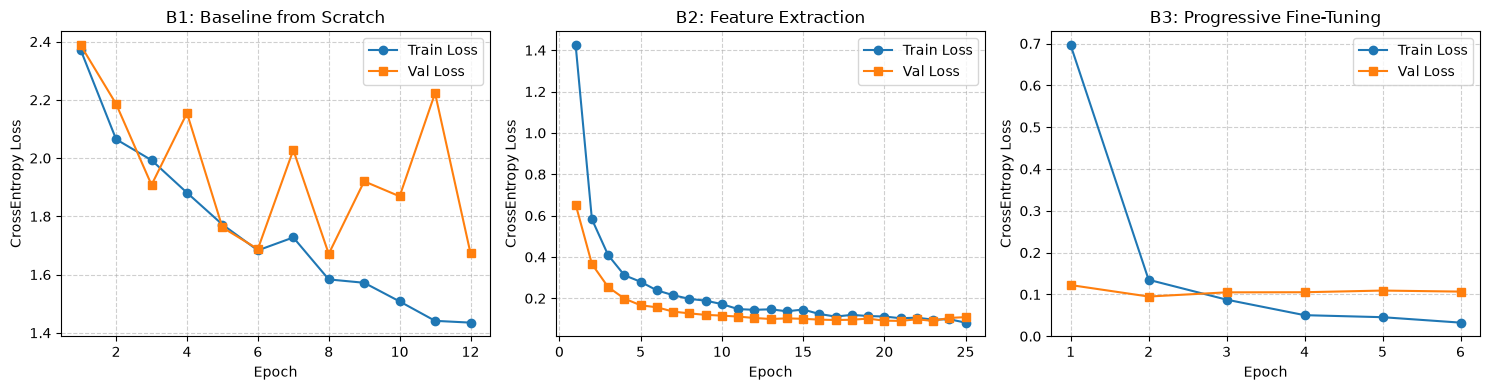


--- Failure Analysis: Sampel Citra Misklasifikasi ---


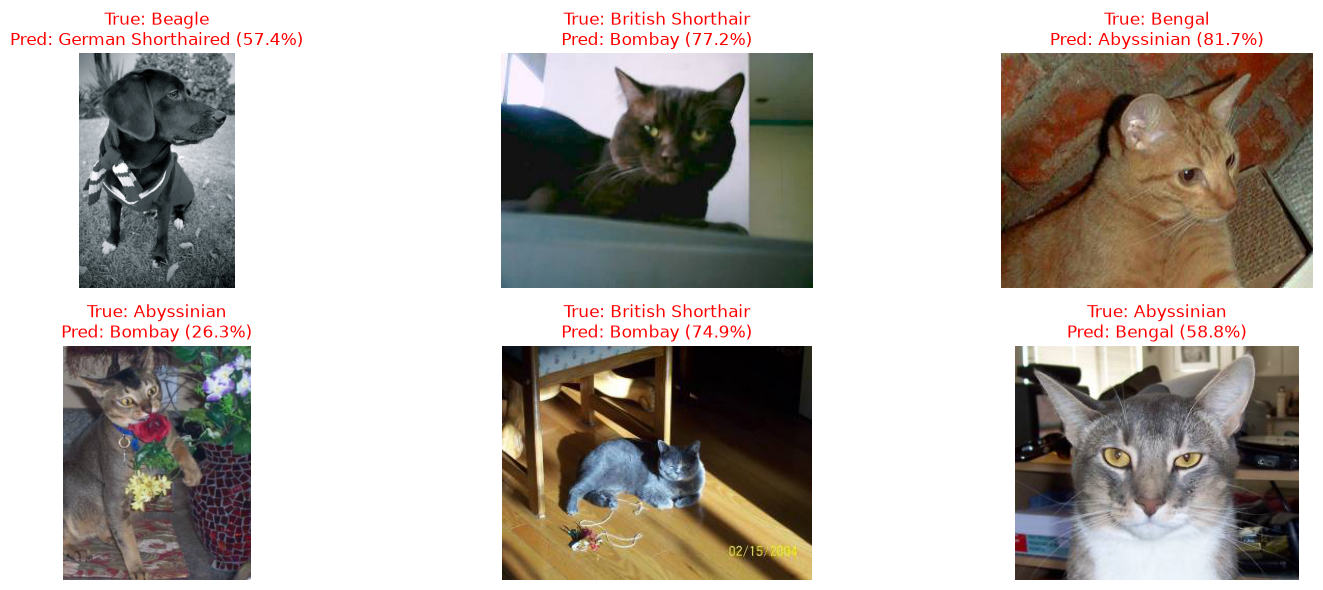

In [ ]:
# 1. Visualisasi Kurva Training vs. Validation Loss (C1)
plt.figure(figsize=(15, 4))

conditions = [('B1', 'B1: Baseline from Scratch'), 
              ('B2', 'B2: Feature Extraction'), 
              ('B3', 'B3: Progressive Fine-Tuning')]

for i, (key, title) in enumerate(conditions, 1):
    plt.subplot(1, 3, i)
    epochs_range = range(1, len(histories[key]['train_loss']) + 1)
    plt.plot(epochs_range, histories[key]['train_loss'], label='Train Loss', marker='o')
    plt.plot(epochs_range, histories[key]['val_loss'], label='Val Loss', marker='s')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('CrossEntropy Loss')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

plt.tight_layout()
plt.savefig("loss_curves_b1_b2_b3.png", dpi=300)
plt.show()

# 2. Failure Analysis Helper (C3: 5 s.d. 8 sampel salah prediksi dari model terbaik B3)
print("\n--- Failure Analysis: Sampel Citra Misklasifikasi ---")
best_model = trained_models['B3']
best_model.eval()

misclassified = []
with torch.no_grad():
    for idx in range(len(test_paths)):
        img_path = test_paths[idx]
        actual_label = y_test[idx]
        
        raw_img = Image.open(img_path).convert("RGB")
        tensor_img = transforms_no_aug(raw_img).unsqueeze(0).to(device)
        
        logits = best_model(tensor_img)
        probs = torch.softmax(logits, dim=1).squeeze(0)
        conf, pred = torch.max(probs, dim=0)
        
        if pred.item() != actual_label:
            misclassified.append({
                'path': img_path,
                'actual': selected_classes[actual_label],
                'pred': selected_classes[pred.item()],
                'confidence': float(conf.item())
            })
        if len(misclassified) >= 6:
            break

# Tampilkan visual misklasifikasi
plt.figure(figsize=(16, 6))
for i, item in enumerate(misclassified[:6]):
    plt.subplot(2, 3, i + 1)
    img = Image.open(item['path'])
    plt.imshow(img)
    plt.title(f"True: {item['actual']}\nPred: {item['pred']} ({item['confidence']*100:.1f}%)", color='red')
    plt.axis('off')
plt.tight_layout()
plt.savefig("failure_analysis_samples.png", dpi=300)
plt.show()